In [1]:
##################
### Keagan Moo ###
### 2024/08/15 ###
### RNA MAST  ###
##################

# This script loads in the MAST results, runs comparisons, and generates figures
suppressPackageStartupMessages(library("Seurat"))
suppressPackageStartupMessages(library("glue"))
suppressPackageStartupMessages(library("SingleCellExperiment"))
suppressPackageStartupMessages(library("scater"))
suppressPackageStartupMessages(library("scran"))
suppressPackageStartupMessages(library("tidyverse"))
suppressPackageStartupMessages(library("data.table"))
suppressPackageStartupMessages(library("MAST"))
suppressPackageStartupMessages(library("lme4"))
suppressPackageStartupMessages(library("rsvd"))
suppressPackageStartupMessages(library("GGally"))
suppressPackageStartupMessages(library("ggrepel"))
suppressPackageStartupMessages(library("DESeq2"))
suppressPackageStartupMessages(library("Matrix"))
suppressPackageStartupMessages(library("RColorBrewer"))
suppressPackageStartupMessages(library("ggupset"))
suppressPackageStartupMessages(library("ggpattern"))
suppressPackageStartupMessages(library("purrr"))

Warning message:
“package ‘ggupset’ was built under R version 4.4.3”
Warning message:
“package ‘ggpattern’ was built under R version 4.4.3”


In [2]:
# Get cell type specific sca file
cDex <- "Type_2a"
sca <- readRDS(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/{cDex}_rna_postDecontx_postArushiQC_PostTPM_1in10nTotal_CDR_sca.rds"))
scaF <- readRDS(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/{cDex}_rna_postDecontx_postArushiQC_PostTPM_1in10nFemale_CDR_sca.rds"))
scaM <- readRDS(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/{cDex}_rna_postDecontx_postArushiQC_PostTPM_1in10nMale_CDR_sca.rds"))

# Arushi indicated this file will give us the nuclei that should be included in the analysis after qc
metadataFactors <- read.table("/nfs/turbo/umms-scjp/kgmoo/data/cluster_info_qc.tsv", sep = "\t", header = TRUE)
batchdataFactors <- read.table("/nfs/turbo/umms-scjp/kgmoo/data/batch-sample-info-full.tsv", sep = "\t", header = TRUE)
dim(metadataFactors)
metadataFactors <- metadataFactors[(metadataFactors$modality == "rna") & (metadataFactors$demux_cat != "multiome"),]
dim(metadataFactors)
metadataFactors <- merge(metadataFactors, batchdataFactors, by = "SNG.1ST")

femDs <- batchdataFactors[batchdataFactors$sex == "F",]$SNG.1ST
memDs <- batchdataFactors[batchdataFactors$sex == "M",]$SNG.1ST
metadataFactorsClustF <- metadataFactors[(metadataFactors$coarse_cluster_name == cDex) & (metadataFactors$SNG.1ST %in% femDs),]
metadataFactorsClustM <- metadataFactors[(metadataFactors$coarse_cluster_name == cDex) & (metadataFactors$SNG.1ST %in% memDs),]

[1] 456880     17

[1] 180583     17

In [22]:
# Generate some summary statistics from the data

print(colnames(colData(sca)))
print(head(colData(sca)))
print(head(counts(sca)))
print(min(counts(sca)))

forCollapse <- data.frame(colData(sca))

readsDF <- data.frame(names(colSums(counts(sca))), colSums(counts(sca)))
colnames(readsDF) <- c("Barcode", "nReads")
head(readsDF)
forCollapse <- merge(forCollapse, readsDF, by = c("Barcode"))

sampledf <- forCollapse %>%
group_by(Sample) %>%
summarise(reads = median(nReads), .groups = "drop")
                     
print("Reads per sample (Cell Type)")
#mean(sampledf$reads)
median(sampledf$reads)

 [1] "Sample"                 "Barcode"                "decontX_contamination" 
 [4] "decontX_clusters"       "id"                     "UMAP_1"                
 [7] "UMAP_2"                 "modality"               "hqaa_umi"              
[10] "fraction_mitochondrial" "sample"                 "coarse_cluster_name"   
[13] "age"                    "sex"                    "batch"                 
[16] "bmi"                    "CDR"                    "wellKey"               
DataFrame with 6 rows and 18 columns
                      Sample          Barcode decontX_contamination
                 <character>      <character>             <numeric>
AAACCCATCCCAGGAC    499-NM-1 AAACCCATCCCAGGAC              0.168473
AAAGAACCAACAAGAT    499-NM-1 AAAGAACCAACAAGAT              0.314403
AAAGGATTCGCAATGT    499-NM-1 AAAGGATTCGCAATGT              0.252359
AAAGTCCAGTTACGTC    499-NM-1 AAAGTCCAGTTACGTC              0.279831
AAAGTGAAGCACAAAT    499-NM-1 AAAGTGAAGCACAAAT              0.316488
AAAGTGA

  [[ suppressing 34 column names ‘AAACCCATCCCAGGAC’, ‘AAAGAACCAACAAGAT’, ‘AAAGGATTCGCAATGT’ ... ]]



                                                                        
ENSG00000230021.10 106.4716 113.1890 . . . 193.8878 . 114.1118  72.61108
ENSG00000237491.9    .        .      . . .   .      .   .        .      
ENSG00000228794.8    .        .      . . . 336.7628 .   .      205.06665
ENSG00000187642.9    .        .      . . .   .      .   .        .      
ENSG00000131584.19 265.5707   .      . . .   .      .   .        .      
ENSG00000127054.20   .      141.2146 . . .   .      .   .       85.55072
                                                                            
ENSG00000230021.10   .      286.6258   .        .        .      73.74192 . .
ENSG00000237491.9    .        .        .        .      136.0515 88.69127 . .
ENSG00000228794.8  263.7134   .      110.4412 181.5073 133.6336 43.86001 . .
ENSG00000187642.9  206.0593   .      195.7094  54.5230   .       .       . .
ENSG00000131584.19   .        .        .        .        .       .       . .
ENSG00000127054.20   .     

,Barcode,nReads
,<chr>,<dbl>
1,AAACCCATCCCAGGAC,935765.6
2,AAAGAACCAACAAGAT,934941.2
3,AAAGGATTCGCAATGT,918886.0
4,AAAGTCCAGTTACGTC,940010.7
5,AAAGTGAAGCACAAAT,925459.4
6,AAAGTGATCCTAGCTC,930663.5


[1] "Reads per sample (Cell Type)"


[1] 936573.5

In [3]:
# Generate a plot tracking the CDR values across batches for signs of systemic technical influence on nuclei emptiness

metaPlot <- colData(sca)
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/MetadataCorr/CDRbyBatch_{cDex}_All_CDR.pdf"), width=6, height=6)
    mygg <- ggplot(data=metaPlot, aes(x=batch, y=CDR)) +
        geom_boxplot(alpha = 0.1)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + #xlim(-0.07,0.07) + ylim(-0.07,0.07) + 
        xlab("Batch") + ylab("CDR") + ggtitle(glue("{cDex} Batch confoundment of CDR")) 
   print(mygg)
dev.off()

pdf 
  2

In [1]:
# Plot age distribution by sex

metadataComp <- readRDS("/nfs/turbo/umms-scjp/kgmoo/data/skeletalmuscleRNA_metadata.rds") %>% dplyr::filter(coarse_cluster_name == cDex)
dim(metadataComp)
Colors <- c("#CC22DD", "#FF2222", "#2222FF")
min(metadataComp$age.x)
max(metadataComp$age.x)

print("Female")
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/AgeHistF.pdf"), width=5, height=6)
    mygg <- ggplot(data=metadataComp[metadataComp$sex.x == "F" ,], aes(x=age.x)) +
        geom_histogram(color = "#FF2222", fill = "#FF2222", binwidth = 1) +
        xlim(c(20,80)) + ylim(c(0,14)) +
        theme_bw() + theme(text=element_text(size=24)) + 
        xlab("Age (Years)") + ylab("Frequency") + ggtitle(glue("")) 
   print(mygg)
dev.off()

print("Male")
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/AgeHistM.pdf"), width=5, height=6)
    mygg <- ggplot(data=metadataComp[metadataComp$sex.x == "M" ,], aes(x=age.x)) +
        geom_histogram(color = "#2222FF", fill = "#2222FF", binwidth = 1) + 
        xlim(c(20,80)) + ylim(c(0,14)) +
        theme_bw() + theme(text=element_text(size=24)) + 
        xlab("Age (Years)") + ylab("Frequency") + ggtitle(glue("")) 
   print(mygg)
dev.off()

ERROR: Error in readRDS("/nfs/turbo/umms-scjp/kgmoo/data/skeletalmuscleRNA_metadata.rds") %>% : could not find function "%>%"


In [3]:
# Load in metadata so we can affix ogtt to our sca objects

metadataComp <- readRDS("/nfs/turbo/umms-scjp/kgmoo/data/skeletalmuscleRNA_metadata.rds") %>% dplyr::filter(coarse_cluster_name == cDex)
metadataCompF <- metadataComp[metadataComp$sex.x == "F",]
metadataCompM <- metadataComp[metadataComp$sex.x == "M",]

colOut <- colData(sca)
colOut <- data.frame(merge(colOut, metadataComp, by.x = "sample", by.y = "sample.x"))
colOut <- colOut %>% dplyr::arrange(id)
sca$ogtt <- colOut$ogtt

colOutF <- colData(scaF)
colOutF <- data.frame(merge(colOutF, metadataCompF, by.x = "sample", by.y = "sample.x"))
colOutF <- colOutF %>% dplyr::arrange(id)
scaF$ogtt <- colOutF$ogtt

colOutM <- colData(scaM)
colOutM <- data.frame(merge(colOutM, metadataCompM, by.x = "sample", by.y = "sample.x"))
colOutM <- colOutM %>% dplyr::arrange(id)
scaM$ogtt <- colOutM$ogtt



[1] "Two"


In [4]:
# Check dimensions
dim(scaF)
dim(scaM)

[1] 2110 8361

[1] 5561 8361

[1]  2370 17776

In [5]:
maxCell <- dim(scaF)[2]
want <- 5000
SubsetV <- c(rep(TRUE, want/2), rep(FALSE, maxCell - want), rep(TRUE, want/2))
scaFall <- subset(scaF, SubsetV)
scaFall$batch <- droplevels(factor(scaFall$batch, levels = unique(scaFall$batch)))
scaFall$sample <- droplevels(factor(scaFall$sample, levels = unique(scaFall$sample)))
scaFall$SNG.1st <- t(data.frame(strsplit(as.character(scaFall$sample), "--")))[,1]

In [4]:
# Load in results from the MAST run
zlmDT <- readRDS(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/{cDex}_rna_postDecontx_postArushiQC_PostTPM_1in10n_resDT_CDR.rds"))
zlmDTF <- readRDS(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/{cDex}_rna_postDecontx_postArushiQC_PostTPM_1in10n_resDTF_CDR.rds"))
zlmDTM <- readRDS(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/{cDex}_rna_postDecontx_postArushiQC_PostTPM_1in10n_resDTM_CDR.rds"))


In [ ]:
# Dissect different C and D coeffecients for comparisons

InspectFrame <- zlmDTF[(zlmDTF$contrast == "age") & (zlmDTF$component %in% c("C", "D", "H", "logFC")),]
InspectFrameC <- InspectFrame[InspectFrame$component == "C",]
colnames(InspectFrameC) <- c("primerid", "component", "contrast", "C.P", "C.ci.hi", "C.ci.lo", "C.coef", "C.z")
InspectFrameD <- InspectFrame[InspectFrame$component == "D",]
colnames(InspectFrameD) <- c("primerid", "component", "contrast", "D.P", "D.ci.hi", "D.ci.lo", "D.coef", "D.z")
InspectFrameH <- InspectFrame[InspectFrame$component == "H",] 
colnames(InspectFrameH) <- c("primerid", "component", "contrast", "H.P", "H.ci.hi", "H.ci.lo", "H.coef", "H.z")
InspectFrameLog <- InspectFrame[InspectFrame$component == "logFC",] 
colnames(InspectFrameLog) <- c("primerid", "component", "contrast", "Log.P", "Log.ci.hi", "Log.ci.lo", "Log.coef", "Log.z")
InspectFrameH <- InspectFrameH %>% select(primerid, H.P)
InspectFrameLog <- InspectFrameLog %>% select(primerid, Log.coef)
InspectFrame <- merge(InspectFrameC, InspectFrameD, by = "primerid")
InspectFrame <- merge(InspectFrame, InspectFrameH, by = "primerid")
InspectFrame <- merge(InspectFrame, InspectFrameLog, by = "primerid")

InspectFrameOld <- zlmDTM[(zlmDTM$contrast == "age") & (zlmDTM$component %in% c("C", "D", "H", "logFC")),]
InspectFrameOldC <- InspectFrameOld[InspectFrameOld$component == "C",]
colnames(InspectFrameOldC) <- c("primerid", "component", "contrast", "C.P", "C.ci.hi", "C.ci.lo", "C.coef", "C.z")
InspectFrameOldD <- InspectFrameOld[InspectFrameOld$component == "D",]
colnames(InspectFrameOldD) <- c("primerid", "component", "contrast", "D.P", "D.ci.hi", "D.ci.lo", "D.coef", "D.z")
InspectFrameOldH <- InspectFrameOld[InspectFrameOld$component == "H",] 
colnames(InspectFrameOldH) <- c("primerid", "component", "contrast", "H.P", "H.ci.hi", "H.ci.lo", "H.coef", "H.z")
InspectFrameOldLog <- InspectFrameOld[InspectFrameOld$component == "logFC",] 
colnames(InspectFrameOldLog) <- c("primerid", "component", "contrast", "Log.P", "Log.ci.hi", "Log.ci.lo", "Log.coef", "Log.z")
InspectFrameOldH <- InspectFrameOldH %>% select(primerid, H.P)
InspectFrameOldLog <- InspectFrameOldLog %>% select(primerid, Log.coef)
InspectFrameOld <- merge(InspectFrameOldC, InspectFrameOldD, by = "primerid")
InspectFrameOld <- merge(InspectFrameOld, InspectFrameOldH, by = "primerid")
InspectFrameOld <- merge(InspectFrameOld, InspectFrameOldLog, by = "primerid")

InspectFrame$C.mod <- -log10(InspectFrame$C.P)*sign(InspectFrame$C.coef)
InspectFrame$D.mod <- -log10(InspectFrame$D.P)*sign(InspectFrame$D.coef)
InspectFrameOld$C.mod <- -log10(InspectFrameOld$C.P)*sign(InspectFrameOld$C.coef)
InspectFrameOld$D.mod <- -log10(InspectFrameOld$D.P)*sign(InspectFrameOld$D.coef)

mandb <- c("#648FFF","#cccccc", "#DC267F")

print("TPM")
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/ModelBreakout/CompareContvDes_neglogp_{cDex}_Fe_Nom_CDR.pdf"), width=6, height=6)
    mygg <- ggplot(data=InspectFrame[InspectFrame$H.P < 0.05,], aes(x=C.mod, y=D.mod)) +
        geom_point(alpha = 0.3, aes(color = Log.coef))+#, position = position_jitter(width = 0.01)) +
        geom_abline(intercept = 0, slope = 1, alpha = 1, col = "black") +
        geom_abline(intercept = 0, slope = -1, alpha = 1, col = "black", linetype="dotted") +
        theme_bw() + #xlim(-0.07,0.07) + ylim(-0.07,0.07) + 
        scale_color_gradientn(colors = mandb, limits=c(-0.1, 0.1)) +
        xlab("signed -log10(p-value) Continous Model") + ylab("signed -log10(p-value) Discrete Model") + ggtitle(glue("{cDex} Female Comparison")) 
   print(mygg)
dev.off()
print("TPM_M")
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/ModelBreakout/CompareContvDes_neglogp_{cDex}_Ma_Nom_CDR.pdf"), width=6, height=6)
    mygg <- ggplot(data=InspectFrameOld[InspectFrameOld$H.P < 0.05,], aes(x=C.mod, y=D.mod)) +
        geom_point(alpha = 0.3, aes(color = Log.coef))+#, position = position_jitter(width = 0.01)) +
        geom_abline(intercept = 0, slope = 1, alpha = 1, col = "black") +
        geom_abline(intercept = 0, slope = -1, alpha = 1, col = "black", linetype="dotted") +
        theme_bw() + #xlim(-0.07,0.07) + ylim(-0.07,0.07) + 
        scale_color_gradientn(colors = mandb, limits=c(-0.1, 0.1)) +
        xlab("signed -log10(p-value) Group Model") + ylab("signed -log10(p-value) Discrete Model") + ggtitle(glue("{cDex} Male Comparison")) 
   print(mygg)
dev.off()

ERROR: Error: object 'zlmDTF' not found


In [48]:
InspectFrame <- merge(InspectFrame, as.data.table(mcols(scaF)), by='primerid')
InspectFrame <- InspectFrame %>% arrange(C.P)
HighSig <- head(InspectFrame, n = 20)
HighCof <- head(InspectFrame[order(-abs(InspectFrame$C.coef)),], n = 2)
HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig, HighCof)
Repel <- rbind(Repel, HardLab)

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/ModelBreakout/MAST_{cDex}_Female_ContOnly_Volcano_1in10n_CDR.pdf"), width=6, height=6)
    mygg <- ggplot(data=InspectFrame, aes(x=C.coef, y=-log10(C.P))) +
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.4)+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        geom_label_repel(data = unique(Repel), aes(x=C.coef, y=-log10(C.P),
                           label = Symbol), size = 2.5, min.segment.length = 0, max.overlaps = 20) +
        theme_bw() + theme(legend.position="none") + #scale_color_manual(values = c(ColorCode_ARIMAUP,ColorCode_Both,ColorCode_GLMUP)) +
        xlab("Continuous Coef") + ylab("-log10(nominal Continuous p-value)") + ggtitle(glue("{cDex} MAST Continuous Model DEG")) +
        xlim(c(-0.08,0.08)) + ylim(c(0,7.5)) 
   print(mygg)
dev.off()

InspectFrame <- InspectFrame %>% arrange(D.P)
HighSig <- head(InspectFrame, n = 20)
HighCof <- head(InspectFrame[order(-abs(InspectFrame$D.coef)),], n = 2)
HardLab <- InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]
Repel <- rbind(HighSig, HighCof)
Repel <- rbind(Repel, HardLab)

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/ModelBreakout/MAST_{cDex}_Female_DicrOnly_Volcano_1in10n_CDR.pdf"), width=6, height=6)
    mygg <- ggplot(data=InspectFrame, aes(x=D.coef, y=-log10(D.P))) +
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.4)+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        geom_label_repel(data = unique(Repel), aes(x=D.coef, y=-log10(D.P),
                           label = Symbol), size = 2.5, min.segment.length = 0, max.overlaps = 20) +
        theme_bw() + theme(legend.position="none") + #scale_color_manual(values = c(ColorCode_ARIMAUP,ColorCode_Both,ColorCode_GLMUP)) +
        xlab("Discrete Coef") + ylab("-log10(nominal Discrete p-value)") + ggtitle(glue("{cDex} MAST Discrete Model DEG")) +
        xlim(c(-0.08,0.08)) + ylim(c(0,7.5))
   print(mygg)
dev.off()

InspectFrameOld <- merge(InspectFrameOld, as.data.table(mcols(scaM)), by='primerid')
InspectFrameOld <- InspectFrameOld %>% arrange(C.P)
HighSig <- head(InspectFrameOld, n = 20)
HighCof <- head(InspectFrameOld[order(-abs(InspectFrameOld$C.coef)),], n = 2)
#HardLab <- datAvBShrunk[(datAvBShrunk$Symbol == "PTPRM") | (datAvBShrunk$Symbol == "KDM5B"),]
Repel <- rbind(HighSig, HighCof)

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/ModelBreakout/MAST_{cDex}_Male_ContOnly_Volcano_1in10n_CDR.pdf"), width=6, height=6)
    mygg <- ggplot(data=InspectFrameOld, aes(x=C.coef, y=-log10(C.P))) +
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.4)+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        geom_label_repel(data = unique(Repel), aes(x=C.coef, y=-log10(C.P),
                           label = Symbol), size = 2.5, min.segment.length = 0, max.overlaps = 20) +
        theme_bw() + theme(legend.position="none") + #scale_color_manual(values = c(ColorCode_ARIMAUP,ColorCode_Both,ColorCode_GLMUP)) +
        xlab("Continuous Coef") + ylab("-log10(nominal Continuous p-value)") + ggtitle(glue("{cDex} MAST Continuous Model DEG")) +
        xlim(c(-0.08,0.08)) + ylim(c(0,7.5)) 
   print(mygg)
dev.off()

InspectFrameOld <- InspectFrameOld %>% arrange(D.P)
HighSig <- head(InspectFrameOld, n = 20)
HighCof <- head(InspectFrameOld[order(-abs(InspectFrameOld$D.coef)),], n = 2)
#HardLab <- datAvBShrunk[(datAvBShrunk$Symbol == "PTPRM") | (datAvBShrunk$Symbol == "KDM5B"),]
Repel <- rbind(HighSig, HighCof)

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/ModelBreakout/MAST_{cDex}_Male_DicrOnly_Volcano_1in10n_CDR.pdf"), width=6, height=6)
    mygg <- ggplot(data=InspectFrameOld, aes(x=D.coef, y=-log10(D.P))) +
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.4)+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        geom_label_repel(data = unique(Repel), aes(x=D.coef, y=-log10(D.P),
                           label = Symbol), size = 2.5, min.segment.length = 0, max.overlaps = 20) +
        theme_bw() + theme(legend.position="none") + #scale_color_manual(values = c(ColorCode_ARIMAUP,ColorCode_Both,ColorCode_GLMUP)) +
        xlab("Discrete Coef") + ylab("-log10(nominal Discrete p-value)") + ggtitle(glue("{cDex} MAST Discrete Model DEG")) +
        xlim(c(-0.08,0.08)) + ylim(c(0,7.5))
   print(mygg)
dev.off()

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“ggrepel: 5 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


pdf 
  2

Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_label_repel()`).”


pdf 
  2

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“ggrepel: 1 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


pdf 
  2

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_label_repel()`).”


pdf 
  2

In [46]:
# Look directly at specific genes across components as they would be plotted
InspectFrame[(InspectFrame$Symbol == "SCAF11") | (InspectFrame$Symbol == "TPRG1"),]

primerid,component.x,contrast.x,C.P,C.ci.hi,C.ci.lo,C.coef,C.z,component.y,contrast.y,⋯,D.ci.lo,D.coef,D.z,H.P,Log.coef,C.mod,D.mod,ID,Symbol,Type
<chr>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<fct>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
ENSG00000188001.10,C,age,2.456555e-03,-0.006499212,-0.029038858,-0.017769035,-3.090259,D,age,⋯,-0.081772208,-0.058902870,-5.0481349,5.356020e-08,-0.08321259,-2.609673,-6.0866280,ENSG00000188001.10,TPRG1,Gene Expression
ENSG00000139218.18,C,age,5.222154e-06,0.010286146,0.004273903,0.007280024,4.746510,D,age,⋯,-0.009984138,-0.003083194,-0.8756698,2.120903e-05,-0.00230407,5.282150,-0.4193096,ENSG00000139218.18,SCAF11,Gene Expression


In [11]:
InspectFrame[(InspectFrame$Symbol == "MICU1") | (InspectFrame$Symbol == "TPRG1"),]
median(InspectFrame$C.coef, na.rm = TRUE)
median(InspectFrame$D.coef, na.rm = TRUE)
head(zlmDTF[(zlmDTF$primerid == "ENSG00000139218.18") & (zlmDTF$contrast == "age"),]) # SCAFF11
head(zlmDTF[(zlmDTF$primerid == "ENSG00000107745.19") & (zlmDTF$contrast == "age"),]) # MICU1
#head(zlmDTF[(zlmDTF$primerid == "ENSG00000227128.4") & (zlmDTF$contrast == "age"),]) # LBX1-AS1

primerid,component.x,contrast.x,C.P,C.ci.hi,C.ci.lo,C.coef,C.z,component.y,contrast.y,D.P,D.ci.hi,D.ci.lo,D.coef,D.z,ID,Symbol,Type
<chr>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
ENSG00000188001.10,C,age,3.549408e-03,-0.005869427,-0.028600018,-0.01723472,-2.972156,D,age,1.176481e-07,-0.038998934,-0.08261545,-0.06080719,-5.464898,ENSG00000188001.10,TPRG1,Gene Expression
ENSG00000107745.19,C,age,7.449998e-05,0.011306802,0.003925739,0.00761627,4.044842,D,age,2.205582e-04,-0.006594155,-0.02047633,-0.01353524,-3.821964,ENSG00000107745.19,MICU1,Gene Expression


[1] 0.003821454

[1] -0.004246367

primerid,component,contrast,Pr(>Chisq),ci.hi,ci.lo,coef,z
<chr>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000139218.18,C,age,4.044067e-06,0.012258601,0.005121643,0.008690122,4.772993
ENSG00000139218.18,D,age,7.115913e-03,-0.002620316,-0.015533622,-0.009076969,-2.755380
ENSG00000139218.18,H,age,6.517137e-07,NA,NA,NA,NA
ENSG00000139218.18,S,age,NA,NA,NA,NA,1.426668
ENSG00000139218.18,logFC,age,NA,0.003490375,-0.008828000,-0.002668812,-0.849264


primerid,component,contrast,Pr(>Chisq),ci.hi,ci.lo,coef,z
<chr>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000107745.19,C,age,7.449998e-05,0.011306802,0.003925739,0.007616270,4.044842
ENSG00000107745.19,D,age,2.205582e-04,-0.006594155,-0.020476328,-0.013535241,-3.821964
ENSG00000107745.19,H,age,4.254397e-07,NA,NA,NA,NA
ENSG00000107745.19,S,age,NA,NA,NA,NA,0.157598
ENSG00000107745.19,logFC,age,NA,0.002470284,-0.008259047,-0.002894382,-1.057453


In [6]:
# Generate the hurdle model specific results from each comparison

fcHurdleF <- merge(zlmDTF[contrast=='age' & component=='H',.(primerid, `Pr(>Chisq)`)], #hurdle P values
                      zlmDTF[contrast=='age' & component=='logFC', .(primerid, coef, ci.hi, ci.lo)], by='primerid')
fcHurdleF[,fdr:=p.adjust(`Pr(>Chisq)`, 'fdr')]
fcHurdleF <- merge(fcHurdleF, as.data.table(mcols(scaF)), by='primerid')
write.table(fcHurdleF, file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/Agg/CSV/F_RNA_Agg_{cDex}.csv"), sep = ",")
fcHurdleFSig <- merge(fcHurdleF[fdr<0.1 & abs(coef)>0], as.data.table(mcols(scaF)), by='primerid')
fcHurdleFSigS <- merge(fcHurdleF[fdr<0.05 & abs(coef)>0], as.data.table(mcols(scaF)), by='primerid')

fcHurdleM <- merge(zlmDTM[contrast=='age' & component=='H',.(primerid, `Pr(>Chisq)`)], #hurdle P values
                      zlmDTM[contrast=='age' & component=='logFC', .(primerid, coef, ci.hi, ci.lo)], by='primerid')
fcHurdleM[,fdr:=p.adjust(`Pr(>Chisq)`, 'fdr')]
fcHurdleM <- merge(fcHurdleM, as.data.table(mcols(scaM)), by='primerid')
write.table(fcHurdleM, file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/Agg/CSV/M_RNA_Agg_{cDex}.csv"), sep = ",")
fcHurdleMSig <- merge(fcHurdleM[fdr<0.1 & abs(coef)>0], as.data.table(mcols(scaM)), by='primerid')
fcHurdleMSigS <- merge(fcHurdleM[fdr<0.05 & abs(coef)>0], as.data.table(mcols(scaM)), by='primerid')

fcHurdle <- merge(zlmDT[contrast=='age' & component=='H',.(primerid, `Pr(>Chisq)`)], #hurdle P values
                      zlmDT[contrast=='age' & component=='logFC', .(primerid, coef, ci.hi, ci.lo)], by='primerid')
fcHurdle[,fdr:=p.adjust(`Pr(>Chisq)`, 'fdr')]
fcHurdle <- merge(fcHurdle, as.data.table(mcols(sca)), by='primerid')
write.table(fcHurdle, file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/Agg/CSV/T_RNA_Agg_{cDex}.csv"), sep = ",")
fcHurdleSig <- merge(fcHurdle[fdr<0.1 & abs(coef)>0], as.data.table(mcols(sca)), by='primerid')
fcHurdleSigS <- merge(fcHurdle[fdr<0.05 & abs(coef)>0], as.data.table(mcols(sca)), by='primerid')

In [16]:
# Check for your favorite gene
fcHurdle[fcHurdle$Symbol == "POMP",]
fcHurdleF[fcHurdleF$Symbol == "POMP",]
fcHurdleM[fcHurdleM$Symbol == "POMP",]

primerid,Pr(>Chisq),coef,ci.hi,ci.lo,fdr,ID,Symbol,Type
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
ENSG00000132963.8,0.2585313,8.853694e-05,0.0008823553,-0.0007052814,0.6124631,ENSG00000132963.8,POMP,Gene Expression


primerid,Pr(>Chisq),coef,ci.hi,ci.lo,fdr,ID,Symbol,Type
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
ENSG00000132963.8,0.004377782,0.0009281546,0.001359049,0.0004972599,0.1021483,ENSG00000132963.8,POMP,Gene Expression


primerid,Pr(>Chisq),coef,ci.hi,ci.lo,fdr,ID,Symbol,Type
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
ENSG00000132963.8,0.01228814,-0.002604792,0.0007019468,-0.005911531,0.1866462,ENSG00000132963.8,POMP,Gene Expression


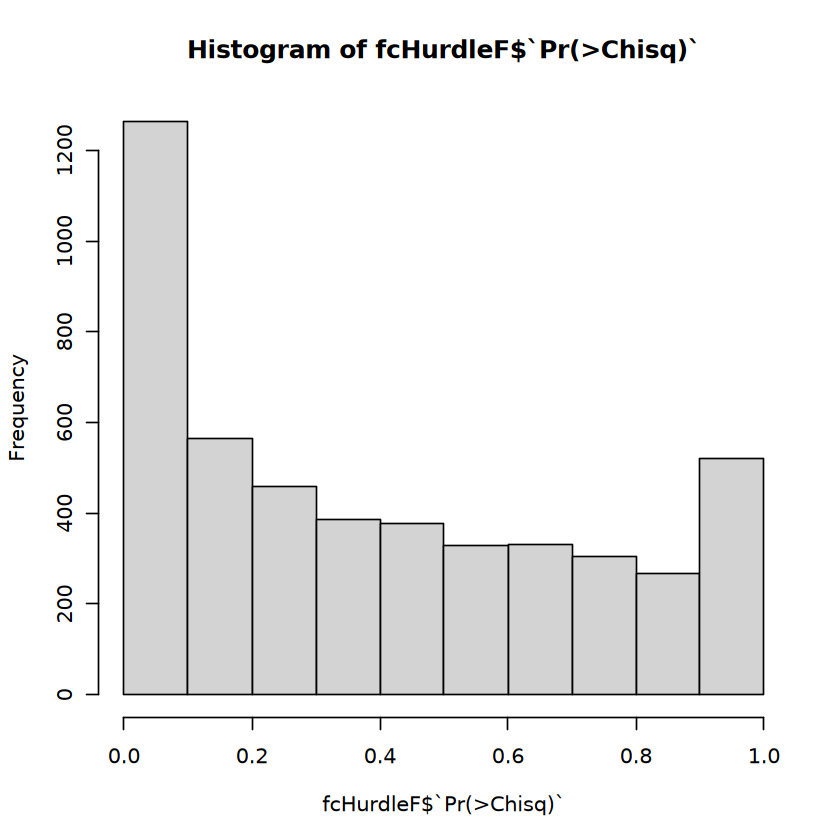

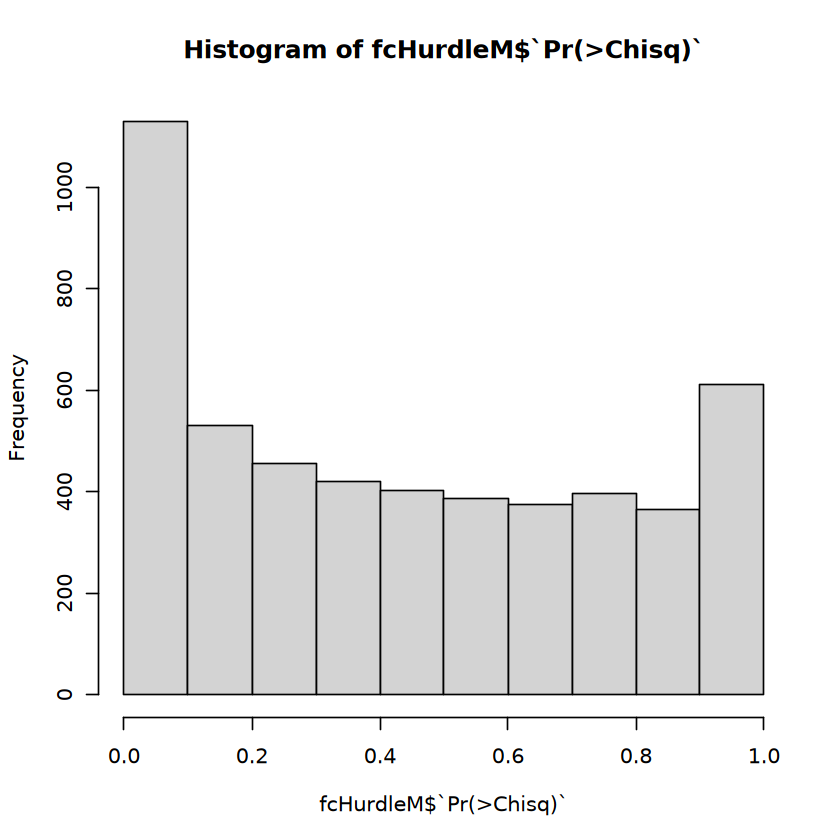

In [9]:
# Check for p-value distributions, note that the hurdle model is combining two p-values from the discrete and continuous models

hist(fcHurdleF$`Pr(>Chisq)`)
hist(fcHurdleM$`Pr(>Chisq)`)

In [7]:
# Summarize counts of FDR adjusted, nominal, and directional hits
nrow(fcHurdleSigS)
nrow(fcHurdleFSigS)
nrow(fcHurdleMSigS)
nrow(fcHurdleSig)
nrow(fcHurdleFSig)
nrow(fcHurdleMSig)
nrow(fcHurdleFSig[fcHurdleFSig$coef < 0,])
nrow(fcHurdleFSig[fcHurdleFSig$coef > 0,])
nrow(fcHurdleMSig[fcHurdleMSig$coef < 0,])
nrow(fcHurdleMSig[fcHurdleMSig$coef > 0,])

[1] 384

[1] 163

[1] 152

[1] 586

[1] 254

[1] 226

[1] 119

[1] 135

[1] 81

[1] 145

In [6]:
# Generate plotting dataframe for a given nuclei type

InspectFrameFSig <- InspectFrame[InspectFrame$primerid %in% fcHurdleFSig$primerid,]
InspectFrameMSig <- InspectFrameOld[InspectFrameOld$primerid %in% fcHurdleMSig$primerid,]

problemFrame <- data.frame(Sex <- c("Female", "Female", "Male", "Male"), 
                           Set <- c("DEG FDR < 0.1", "Opposed Coef", "DEG FDR < 0.1", "Opposed Coef"), 
                           Val <- c(nrow(InspectFrameFSig), nrow(InspectFrameFSig[(InspectFrameFSig$D.coef)*(InspectFrameFSig$C.coef)< 0,]),
                                   nrow(InspectFrameMSig), nrow(InspectFrameMSig[(InspectFrameMSig$D.coef)*(InspectFrameMSig$C.coef)< 0,])))
colnames(problemFrame) <- c("Sex", "Set", "Val")
problemFrame

ERROR: Error: object 'InspectFrame' not found


In [8]:
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/MAST_{cDex}_GoodVBad_1in10n_CDR.pdf"), width=5, height=5)
mygg <- ggplot(problemFrame, aes(fill = Set, x = Sex, y = Val)) +
  geom_bar(position = 'dodge', stat = "identity") +
  xlab("Comparison") + ylab("Number of Genes") + ggtitle(glue("{cDex} DEGs with opposed coefs")) +
  #scale_fill_manual(values = c("#CC8000","#315CCC","#A9034C","#000000")) +
  scale_y_continuous(breaks=seq(0,500,100), limits = c(0,500)) + theme_bw()
mygg
dev.off()

pdf 
  2

In [8]:
# Generate labeled volcano plots for all comparisons

datAvBShrunk <- fcHurdle %>% arrange(fdr)

# Set which genes are going to be labeled, change the numbers in the following lines to emphasize small p-values, high coefficients of change or both
HighSig <- head(datAvBShrunk, n = 20)
HighCof <- head(datAvBShrunk[order(-abs(datAvBShrunk$coef)),], n = 2)
#HardLab <- datAvBShrunk[(datAvBShrunk$Symbol == "PTPRM") | (datAvBShrunk$Symbol == "KDM5B"),]
Repel <- rbind(HighSig, HighCof)
#Repel <- rbind(Repel, HardLab)

datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$fdr < 0.1))
datAvBShrunk <- datAvBShrunk %>% arrange(-fdr)
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/MAST_{cDex}_All_Volcano_1in10n_CDR.pdf"), width=6, height=6)
    mygg <- ggplot(data=datAvBShrunk, aes(x=coef, y=-log10(`Pr(>Chisq)`))) +
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.4, aes(color = ColorCode))+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        geom_label_repel(data = unique(Repel), aes(x=coef, y=-log10(`Pr(>Chisq)`),
                           label = Symbol), size = 2.5, min.segment.length = 0, max.overlaps = 20) +
        theme_bw() + theme(legend.position="none", text=element_text(size=24)) + #scale_color_manual(values = c(ColorCode_ARIMAUP,ColorCode_Both,ColorCode_GLMUP)) +
        xlab("Coef") + ylab("-log10(nominal p-value)") + ggtitle(glue("{cDex} MAST Differential Expression")) +
        xlim(c(-0.07,0.07))#ylim(c(-5,5)) +
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_label_repel()`).”


pdf 
  2

In [7]:
# Volcano Plot
InspectMerge <- InspectFrame %>% select(primerid, C.coef, D.coef) %>% arrange(primerid)
fcHurdleFMerge <- merge(fcHurdleF, InspectMerge)

#scaFCounts <- data.frame(counts(scaF))
#ZeroNuc <- rowSums(scaFCounts==0)
#TotNuc <- ncol(scaFCounts)
#ZeroP <- ZeroNuc/TotNuc
#ZeroP <- data.frame(ZeroP) %>% arrange(row.names(.))
#ZeroP$primerid <- rownames(ZeroP)
#max(ZeroP$ZeroP)
#min(ZeroP$ZeroP)

#fcHurdleFMerge2 <- merge(fcHurdleFMerge, ZeroP)
datAvBShrunk <- fcHurdleFMerge %>% arrange(fdr)

mandb <- c("#648FFF","#dddddd", "#DC267F")

HighSig <- head(datAvBShrunk, n = 5)
HighCof <- head(datAvBShrunk[order(-abs(datAvBShrunk$coef)),], n = 0)
#HardLab <- datAvBShrunk[(datAvBShrunk$Symbol == "PTPRM") | (datAvBShrunk$Symbol == "KDM5B"),]
Repel <- rbind(HighSig, HighCof)
#Repel <- rbind(Repel, HardLab)

datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$fdr < 0.05))
datAvBShrunk <- datAvBShrunk %>% arrange(-fdr)
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/MAST_{cDex}_Female_VolcanoFDR005_1in10n_CDR.pdf"), width=4, height=6)
    mygg <- ggplot(data=datAvBShrunk, aes(x=coef, y=-log10(`Pr(>Chisq)`))) +
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.4, aes(color = ColorCode))+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        geom_label_repel(data = unique(Repel), aes(x=coef, y=-log10(`Pr(>Chisq)`),
                           label = Symbol), size = 4, min.segment.length = 0, max.overlaps = 20, force = 5) +
        theme_bw() + theme(legend.position="none", text=element_text(size=24)) + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        ylim(c(0,11)) + scale_x_continuous(breaks = c(-0.1, 0, 0.1) , limits = c(-0.13,0.13))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

datAvBShrunkF <- datAvBShrunk

InspectOldMerge <- InspectFrameOld %>% select(primerid, C.coef, D.coef) %>% arrange(primerid)
fcHurdleMMerge <- merge(fcHurdleM, InspectOldMerge)

#scaMCounts <- data.frame(counts(scaM))
#ZeroNuc <- rowSums(scaMCounts==0)
#TotNuc <- ncol(scaMCounts)
#ZeroP <- ZeroNuc/TotNuc
#ZeroP <- data.frame(ZeroP) %>% arrange(row.names(.))
#ZeroP$primerid <- rownames(ZeroP)
#max(ZeroP$ZeroP)
#min(ZeroP$ZeroP)

#fcHurdleMMerge2 <- merge(fcHurdleMMerge, ZeroP, by = "primerid")
datAvBShrunk <- fcHurdleMMerge %>% arrange(fdr)
HighSig <- head(datAvBShrunk, n = 5)
HighCof <- head(datAvBShrunk[order(-abs(datAvBShrunk$coef)),], n = 0)
#HardLab <- datAvBShrunk[(datAvBShrunk$Symbol == "INS") | (datAvBShrunk$Symbol == "GCG"),]
Repel <- rbind(HighSig, HighCof)
#Repel <- rbind(Repel, HardLab)

datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$fdr < 0.05))
datAvBShrunk <- datAvBShrunk %>% arrange(-fdr)
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/MAST_{cDex}_Male_VolcanoFDR005_1in10n_CDR.pdf"), width=4, height=6)
    mygg <- ggplot(data=datAvBShrunk, aes(x=coef, y=-log10(`Pr(>Chisq)`))) +
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.4, aes(color = ColorCode))+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        geom_label_repel(data = unique(Repel), aes(x=coef, y=-log10(`Pr(>Chisq)`),
                           label = Symbol), size = 4, min.segment.length = 0, max.overlaps = 20, force = 5) +
        theme_bw() + theme(legend.position="none", text=element_text(size=24)) + 
        xlab("") + ylab("") + ggtitle(glue("")) +
        ylim(c(0,11)) + scale_x_continuous(breaks = c(-0.1, 0, 0.1) , limits = c(-0.13,0.13))
        #scale_color_gradientn(colors = mandb, limits=c(0, 1))
   print(mygg)
dev.off()

Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

In [9]:
# Generate count frames for plotting an individual gene's expression across time points within a specific sex dataset
scaFCounts <- data.frame(counts(scaF))
scaFLogCounts <- data.frame(logcounts(scaF))

metadataJustAge <- metadataFactorsClustF %>% select(barcode, age, SNG.1ST)


# Barcodes from scaFCounts that don't match to one from the metadata get assigned to an NA SNG.1ST
metadataJustAge <- metadataJustAge[match(colnames(scaFCounts), metadataJustAge$barcode),]
metadataJustAgeS <- metadataJustAge %>% select(age, SNG.1ST) %>% unique() %>% arrange(age)

scaFCounts <- rbind(scaFCounts, metadataJustAge$age)
scaFCounts <- rbind(scaFCounts, metadataJustAge$SNG.1ST)
scaFCounts <- data.frame(t(scaFCounts))
scaFCounts$X5562 <- factor(scaFCounts$X5562, levels=metadataJustAgeS$SNG.1ST)

scaFLogCounts <- rbind(scaFLogCounts, metadataJustAge$age)
scaFLogCounts <- rbind(scaFLogCounts, metadataJustAge$SNG.1ST)
scaFLogCounts <- data.frame(t(scaFLogCounts))
scaFLogCounts$X5562 <- factor(scaFLogCounts$X5562, levels=metadataJustAgeS$SNG.1ST)


ERROR: Error in `$<-.data.frame`(`*tmp*`, X5563, value = structure(integer(0), levels = c("32071", : replacement has 0 rows, data has 19547


In [18]:
coords <- "ENSG00000177606.6"

# 0 in TPM counts will be 0 in log2(TPM+1) counts
Nuc0P <- sum(scaMCounts$ENSG00000177606.6 == 0)/nrow(scaMCounts)*100
Nuc0P

scaFLogCounts <- scaMLogCounts[!(is.na(scaMLogCounts$X5563)),]
scaFCounts <- scaMCounts[!(is.na(scaMCounts$X5563)),]

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/TPMTestPlots/{coords}_Female_{cDex}_TPM.pdf"), width=6, height=6)
mygg <- ggplot(data=scaFCounts, aes(x=X5562, y=as.numeric(ENSG00000107745.19))) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_point(alpha = 0.1) + theme_bw() +
  xlab("Age") + ylab("Gene TPM Post DecontX Counts")+ ggtitle(coords)
mygg
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/TPMTestPlots/{coords}_Female_{cDex}_log2TPM1.pdf"), width=6, height=6)
mygg <- ggplot(data=scaFLogCounts, aes(x=X5562, y=as.numeric(ENSG00000107745.19))) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_point(alpha = 0.1) + theme_bw() +
  xlab("Age") + ylab("Gene log2(TPM+1) Post DecontX Counts")+ ggtitle(coords)
mygg
dev.off()

[1] 28.56115

pdf 
  2

pdf 
  2

In [8]:
# Genes per sample plots

scaFLogCounts <- data.frame(logcounts(scaF))
scaMLogCounts <- data.frame(logcounts(scaM))
scaFNucleiGs <- data.frame(colSums(scaFLogCounts > 0))
scaMNucleiGs <- data.frame(colSums(scaMLogCounts > 0))

metadataFJustAge <- metadataFactorsClustF %>% select(barcode, age, SNG.1ST)
metadataMJustAge <- metadataFactorsClustM %>% select(barcode, age, SNG.1ST)

# Barcodes from scaFCounts that don't match to one from the metadata get assigned to an NA SNG.1ST
metadataFJustAge <- metadataFJustAge[match(colnames(scaFLogCounts), metadataFJustAge$barcode),]
metadataFJustAge <- metadataFJustAge[complete.cases(metadataFJustAge),]
metadataFJustAgeS <- metadataFJustAge %>% select(age, SNG.1ST) %>% unique() %>% arrange(age)
rownames(metadataFJustAge) <- metadataFJustAge$barcode

metadataMJustAge <- metadataMJustAge[match(colnames(scaMLogCounts), metadataMJustAge$barcode),]
metadataMJustAge <- metadataMJustAge[complete.cases(metadataMJustAge),]
metadataMJustAgeS <- metadataMJustAge %>% select(age, SNG.1ST) %>% unique() %>% arrange(age)
rownames(metadataMJustAge) <- metadataMJustAge$barcode

nucGsF <- merge(scaFNucleiGs, metadataFJustAge, by = "row.names") #data.frame(Gs = scaFNucleiGs, age = metadataFJustAge$age, sample = metadataFJustAge$SNG.1ST)
nucGsF$Row.names <- NULL
colnames(nucGsF)[1] <- "GeneCount"

nucGsM <- merge(scaFNucleiGs, metadataFJustAge, by = "row.names") #data.frame(Gs = scaMNucleiGs, age = metadataMJustAge$age, sample = metadataMJustAge$SNG.1ST)
nucGsM$Row.names <- NULL
colnames(nucGsM)[1] <- "GeneCount"


In [7]:
scaFLogCountS <- data.frame(t(scaFLogCounts))
metadataFJustSamp <- metadataFJustAge %>% select(SNG.1ST)
scaFLogCountS <- merge(scaFLogCountS, metadataFJustSamp, by = "row.names")
scaFLogCountS$Row.names <- NULL

scaMLogCountS <- data.frame(t(scaMLogCounts))
metadataMJustSamp <- metadataMJustAge %>% select(SNG.1ST)
scaMLogCountS <- merge(scaMLogCountS, metadataMJustSamp, by = "row.names")
scaMLogCountS$Row.names <- NULL

In [8]:
metadataFJustSamp <- metadataFJustAge %>% select(SNG.1ST, age) %>% unique()
sampList <- unique(metadataFJustSamp$SNG.1ST)
sampInit <- sampList[1]
sampList <- sampList[-1]

seedFrame <- (scaFLogCountS[scaFLogCountS$SNG.1ST == sampInit,])
seedFrame$SNG.1ST <- NULL

seedVec <- colSums(seedFrame)
seedVal <- sum(seedVec != 0)
valVec <- c(seedVal)

for (sampleDex in sampList) {

    tempFrame <- (scaFLogCountS[scaFLogCountS$SNG.1ST == sampleDex,])
    tempFrame$SNG.1ST <- NULL

    tempVec <- colSums(tempFrame)
    tempVal <- sum(tempVec != 0)
    valVec <- c(valVec, tempVal)
    
}

sampleGsF <- data.frame(sample = metadataFJustSamp$SNG.1ST, age = metadataFJustSamp$age, Gs = valVec)

metadataMJustSamp <- metadataMJustAge %>% select(SNG.1ST, age) %>% unique()
sampList <- unique(metadataMJustSamp$SNG.1ST)
sampInit <- sampList[1]
sampList <- sampList[-1]

seedfraMe <- (scaMLogCountS[scaMLogCountS$SNG.1ST == sampInit,])
seedfraMe$SNG.1ST <- NULL

seedVec <- colSums(seedfraMe)
seedVal <- sum(seedVec != 0)
valVec <- c(seedVal)

for (sampleDex in sampList) {

    tempfraMe <- (scaMLogCountS[scaMLogCountS$SNG.1ST == sampleDex,])
    tempfraMe$SNG.1ST <- NULL

    tempVec <- colSums(tempfraMe)
    tempVal <- sum(tempVec != 0)
    valVec <- c(valVec, tempVal)
    
}

sampleGsM <- data.frame(sample = metadataMJustSamp$SNG.1ST, age = metadataMJustSamp$age, Gs = valVec)

In [27]:
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/GenesPerSample_Female_{cDex}.pdf"), width=6, height=6)
mygg <- ggplot(data=sampleGsF, aes(x=age, y=as.numeric(Gs))) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_point(alpha = 0.2) + theme_bw() + #ylim(c(0,6000)) +
  xlab("Age") + ylab("Total Number of Genes with Counts")+ ggtitle(glue("{cDex} Female genes per sample"))
mygg
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/GenesPerSample_Male_{cDex}.pdf"), width=6, height=6)
mygg <- ggplot(data=sampleGsM, aes(x=age, y=as.numeric(Gs))) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_point(alpha = 0.2) + theme_bw() + #ylim(c(0,6000)) +
  xlab("Age") + ylab("Total Number of Genes with Counts")+ ggtitle(glue("{cDex} Male genes per sample"))
mygg
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/GenesPerNuclei_Female_{cDex}.pdf"), width=6, height=6)
mygg <- ggplot(data=nucGsF, aes(x=age, y=as.numeric(GeneCount))) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_point(alpha = 0.05) + theme_bw() +
  xlab("Age") + ylab("Total Number of Genes with Counts")+ ggtitle(glue("{cDex} Female genes per nuclei"))
mygg
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/GenesPerNuclei_Male_{cDex}.pdf"), width=6, height=6)
mygg <- ggplot(data=nucGsM, aes(x=age, y=as.numeric(GeneCount))) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_point(alpha = 0.2) + theme_bw() +
  xlab("Age") + ylab("Total Number of Genes with Counts")+ ggtitle(glue("{cDex} Male genes per nuclei"))
mygg
dev.off()

pdf 
  2

pdf 
  2

pdf 
  2

pdf 
  2

pdf 
  2

pdf 
  2

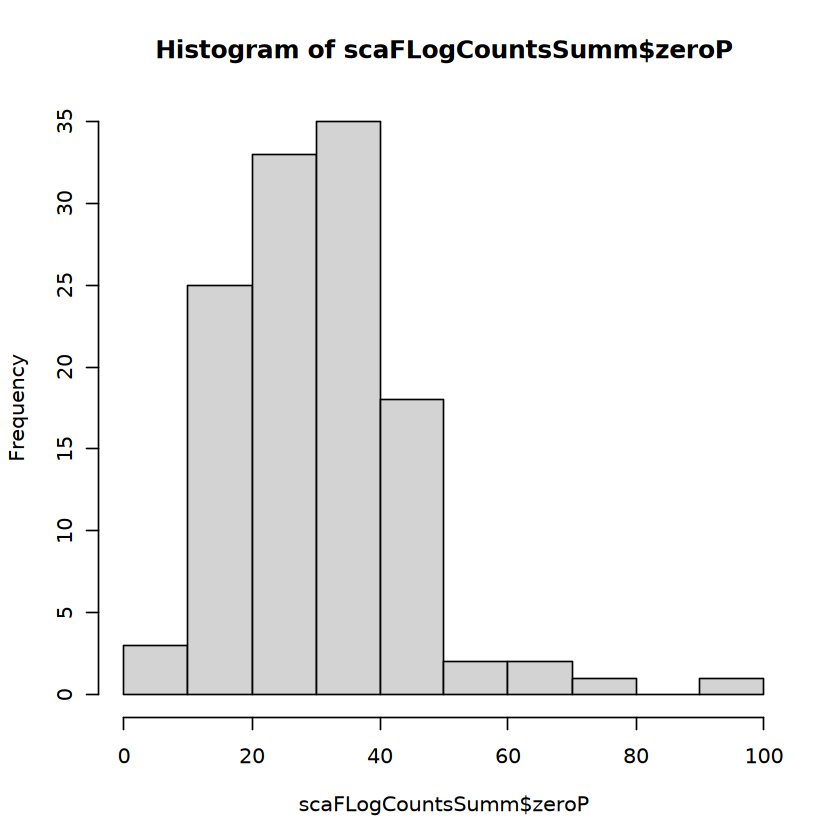

In [19]:
# Box plots tracking individual gene expression within a sex but this time with transforms applied

coords <- "ENSG00000107745.19"
scaFLogCountsSumm <- scaFLogCounts %>% group_by(X5563) %>% summarize(
    age = median(as.numeric(X5562)),
    averageS = median(as.numeric(ENSG00000107745.19)), 
    minS = min(as.numeric(ENSG00000107745.19)), 
    maxS = max(as.numeric(ENSG00000107745.19)),
    zeroP = (sum(ENSG00000107745.19 == 0)/sum(ENSG00000107745.19 != 9999999))*100)
scaFLogCountsSumm <- scaFLogCountsSumm[!(is.na(scaFLogCountsSumm$X5563)),]
#scaFLogCountsSumm
hist(scaFLogCountsSumm$zeroP)


#pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/TPMTestPlots/{coords}_Female_{cDex}_log2TPM1_Samp.pdf"), width=10, height=8)
#mygg <- ggplot(data=scaFLogCountsSumm, aes(x=X5563, y=averageS, color = zeroP)) +
#  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
#  geom_point(alpha = 0.9) + theme_bw() +
#  xlab("Sample") + ylab("Median Gene log2(TPM+1) Post DecontX Counts")+ ggtitle(coords) +
#  theme(axis.text.x = element_text(size = 6, angle = 90, vjust = 0.5, hjust=1))
#mygg
#dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/TPMTestPlots/{coords}_Female_{cDex}_log2TPM1_SampBox.pdf"), width=10, height=8)
mygg <- ggplot(data=scaFLogCounts, aes(x=X5563, y=as.numeric(ENSG00000107745.19))) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_boxplot() + theme_bw() +
  xlab("Sample") + ylab("Gene log2(TPM+1) Post DecontX Counts")+ ggtitle(coords) +
  theme(axis.text.x = element_text(size = 6, angle = 90, vjust = 0.5, hjust=1))
mygg
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/TPMTestPlots/{coords}_Female_{cDex}_TPM_SampBox.pdf"), width=10, height=8)
mygg <- ggplot(data=scaFCounts, aes(x=X5563, y=as.numeric(ENSG00000107745.19))) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_boxplot() + theme_bw() +
  xlab("Sample") + ylab("Gene TPM Post DecontX Counts")+ ggtitle(coords) +
  theme(axis.text.x = element_text(size = 6, angle = 90, vjust = 0.5, hjust=1))
mygg
dev.off()

In [11]:
# plotting an individual gene's expression as seen through the continuous and discrete models of MAST

coords <- "ENSG00000107745.19" #SCAF11
TotalFrame <- data.frame(counts = logcounts(scaF)[coords,], age = colData(scaF)$age, sample = colData(scaF)$sample) %>% arrange(age)

DiscFrame <- TotalFrame
DiscFrame$counts <- as.numeric(TotalFrame$counts == 0)
DiscFrame <- DiscFrame %>% group_by(sample) %>% summarize(zeroP = sum(counts)/length(counts), age = mean(age)) %>% arrange(age)
ContFrame <- TotalFrame[TotalFrame$counts > 0,]

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/TPMTestPlots/{coords}_Female_{cDex}_log2TPM1_Cont.pdf"), width=6, height=6)
mygg <- ggplot(data=ContFrame, aes(x=age, y=as.numeric(counts))) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_point(alpha = 0.05) + theme_bw() +
  xlab("Age") + ylab("Gene log2(TPM+1) Post DecontX Counts")+ ggtitle(coords)
mygg
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/TPMTestPlots/{coords}_Female_{cDex}_ZeroP_Disc.pdf"), width=10, height=8)
mygg <- ggplot(data=DiscFrame, aes(x=age, y=as.numeric(zeroP))) +
  #geom_errorbar(aes(ymin = log2FC_CL, ymax = log2FC_CU)) + 
  geom_point() + theme_bw() +
  xlab("Sample") + ylab("Percent 0 read nuclei")+ ggtitle(coords) +
  theme(axis.text.x = element_text(size = 6, angle = 90, vjust = 0.5, hjust=1))
mygg
dev.off()

pdf 
  2

pdf 
  2

In [7]:
# Load in previously generated DESeq2 DEG results to compare

DESeq2FRes <- data.frame(readRDS(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/linear_per_cluster/{cDex}_DESeq.rds"))[[1]])
nrow(DESeq2FRes)
DESeq2FRes$Temp <- rownames(DESeq2FRes)
#DESeq2FRes <- DESeq2FRes[DESeq2FRes$Temp %in% fcHurdleF$primerid,]
DESeq2FRes <- merge(DESeq2FRes, as.data.table(mcols(scaF)), by.x = "Temp", by.y = "primerid")
#DESeq2FRes[is.na(DESeq2FRes$padj),]$padj <- 1
DESeq2FRes <- DESeq2FRes %>% arrange(padj)
#head(DESeq2FRes)
nrow(DESeq2FRes[DESeq2FRes$padj < 0.05,])

DESeq2MRes <- data.frame(readRDS(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/linear_per_cluster/{cDex}_DESeq.rds"))[[2]])
#nrow(DESeq2MRes)
DESeq2MRes$Temp <- rownames(DESeq2MRes)
#DESeq2MRes <- DESeq2MRes[DESeq2MRes$Temp %in% fcHurdleM$primerid,]
DESeq2MRes <- merge(DESeq2MRes, as.data.table(mcols(scaM)), by.x = "Temp", by.y = "primerid")
DESeq2MRes <- DESeq2MRes %>% arrange(padj)
#DESeq2MRes[is.na(DESeq2MRes$padj),]$padj <- 1
nrow(DESeq2MRes)
nrow(DESeq2MRes[DESeq2MRes$padj < 0.05,])

[1] 9459

[1] 2903

[1] 5929

[1] 38

In [7]:
# Format results from MAST to export for LR-Path and downstream KEGG term enrichment tests

#DESeq2GoEx <- DESeq2Res %>% select(Temp, Symbol, pvalue, log2FoldChange, padj)
MASTGoEx <- fcHurdle %>% select(primerid, Symbol, 'Pr(>Chisq)', coef, fdr)
#write.csv(DESeq2GoEx, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_DESEq2_Total_GoExNom.csv"))
write.csv(MASTGoEx, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Total_GoExNom.csv"))
MASTGoExUp <- MASTGoEx %>% filter(coef > 0)
MASTGoExDw <- MASTGoEx %>% filter(coef < 0)
write.csv(MASTGoExUp, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Total_Up_GoExNom.csv"))
write.csv(MASTGoExDw, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Total_Down_GoExNom.csv"))


#DESeq2FGoEx <- DESeq2FRes %>% select(Temp, Symbol, pvalue, log2FoldChange, padj)
MASTFGoEx <- fcHurdleF %>% select(primerid, Symbol, 'Pr(>Chisq)', coef, fdr)
#write.csv(DESeq2FGoEx, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_DESEq2_Female_GoExNom.csv"))
write.csv(MASTFGoEx, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Female_GoExNom.csv"))
MASTFGoExUp <- MASTFGoEx %>% filter(coef > 0)
MASTFGoExDw <- MASTFGoEx %>% filter(coef < 0)
write.csv(MASTFGoExUp, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Female_Up_GoExNom.csv"))
write.csv(MASTFGoExDw, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Female_Down_GoExNom.csv"))

#DESeq2MGoEx <- DESeq2MRes %>% select(Temp, Symbol, pvalue, log2FoldChange, padj)
MASTMGoEx <- fcHurdleM %>% select(primerid, Symbol, 'Pr(>Chisq)', coef, fdr)
#write.csv(DESeq2MGoEx, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_DESEq2_Male_GoExNom.csv"))
write.csv(MASTMGoEx, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Male_GoExNom.csv"))
MASTMGoExUp <- MASTMGoEx %>% filter(coef > 0)
MASTMGoExDw <- MASTMGoEx %>% filter(coef < 0)
write.csv(MASTMGoExUp, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Male_Up_GoExNom.csv"))
write.csv(MASTMGoExDw, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Male_Down_GoExNom.csv"))


In [8]:
# Volcano Plots for DESeq2

datAvBShrunk <- DESeq2FRes %>% arrange(padj)
HighSig <- head(datAvBShrunk, n = 14)
HighCof <- head(datAvBShrunk[order(-abs(datAvBShrunk$log2FoldChange)),], n = 1)
#HardLab <- datAvBShrunk[(datAvBShrunk$SYMBOL == "INS") | (datAvBShrunk$SYMBOL == "GCG"),]
Repel <- rbind(HighSig, HighCof)
#Repel <- rbind(Repel, HardLab)

datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$padj < 0.1))

unique(datAvBShrunk$ColorCode)

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/DESeq2_{cDex}_Female_Volcano.pdf"), width=6, height=6)
    mygg <- ggplot(data=datAvBShrunk, aes(x=log2FoldChange, y=-log10(pvalue))) +
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.4, aes(color = ColorCode))+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        geom_label_repel(data = unique(Repel), aes(x=log2FoldChange, y=-log10(pvalue),
                           label = Symbol), size = 2.5, min.segment.length = 0, max.overlaps = 20) +
        theme_bw() + theme(legend.position="none") + #scale_color_manual(values = c(ColorCode_ARIMAUP,ColorCode_Both,ColorCode_GLMUP)) +
        xlab("log2 Fold Change") + ylab("-log10(nominal p-value)") + ggtitle(glue("{cDex} Fiber DESeq2 Differential Expression")) +
        xlim(c(-0.1,0.1)) #ylim(c(-5,5)) +
   print(mygg)
dev.off()

datAvBShrunk <- DESeq2MRes %>% arrange(padj)
HighSig <- head(datAvBShrunk, n = 14)
HighCof <- head(datAvBShrunk[order(-abs(datAvBShrunk$log2FoldChange)),], n = 1)
#HardLab <- datAvBShrunk[(datAvBShrunk$SYMBOL == "INS") | (datAvBShrunk$SYMBOL == "GCG"),]
Repel <- rbind(HighSig, HighCof)
#Repel <- rbind(Repel, HardLab)

datAvBShrunk$ColorCode <- as.factor(as.numeric(datAvBShrunk$padj < 0.1))

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/DESeq2_{cDex}_Male_Volcano.pdf"), width=6, height=6)
    mygg <- ggplot(data=datAvBShrunk, aes(x=log2FoldChange, y=-log10(pvalue))) +
        scale_color_manual(values = c("#000000","#FF0000")) +
        geom_point(alpha = 0.4, aes(color = ColorCode))+#, position = position_jitter(width = 0.01)) +
        #geom_vline(xintercept = 1, linetype='dashed') + geom_vline(xintercept = -1, linetype='dashed') +
        geom_label_repel(data = unique(Repel), aes(x=log2FoldChange, y=-log10(pvalue),
                           label = Symbol), size = 2.5, min.segment.length = 0, max.overlaps = 20) +
        theme_bw() + theme(legend.position="none") + #scale_color_manual(values = c(ColorCode_ARIMAUP,ColorCode_Both,ColorCode_GLMUP)) +
        xlab("log2 Fold Change") + ylab("-log10(nominal p-value)") + ggtitle(glue("{cDex} Fiber DESeq2 Differential Expression")) +
        xlim(c(-0.1,0.1)) #ylim(c(-5,5)) +
   print(mygg)
dev.off()

[1] 1 0
Levels: 0 1

pdf 
  2

pdf 
  2

In [19]:
cDex
nrow(fcHurdleM)

[1] "Type_1"

[1] 6636

In [9]:
# Generate -log10(p-value) comparison plots between MAST and DESeq2 results

print("MAST or DESeq2")
CompDF <- merge(fcHurdleF,DESeq2FRes, by.x = "primerid", by.y = "Temp") %>% dplyr::select(primerid, `Pr(>Chisq)`, fdr, coef, pvalue, padj, log2FoldChange)
colnames(CompDF) <- c("Row.names", "ChP", "fdr", "coef", "pvalue", "padj", "log2FoldChange")
CompDF$modp.MAST <- -log10(CompDF$ChP)*sign(CompDF$coef)
CompDF$modp.DESeq <- -log10(CompDF$pvalue)*sign(CompDF$log2FoldChange)
if (nrow(CompDF[(is.na(CompDF$fdr)),]) > 0) {
    CompDF[(is.na(CompDF$FDR)),]$fdr <- 1
}
if (nrow(CompDF[(is.na(CompDF$padj)),]) > 0) {
    CompDF[(is.na(CompDF$padj)),]$padj <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$fdr < 0.05,]$ColorBlock <- "FDR < 0.05 with MAST"
CompDF[CompDF$padj < 0.05,]$ColorBlock <- "FDR < 0.05 with DESeq2"
CompDF[(CompDF$padj < 0.05) & (CompDF$fdr < 0.05),]$ColorBlock <- "FDR < 0.05 with Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/CompareMASTCDRvDESeqFDRP005_{cDex}_FeLedge.pdf"), width=7, height=7)
    mygg <- ggplot(data=CompDF, aes(x=-log10(ChP)*sign(coef), y=-log10(pvalue)*sign(log2FoldChange))) +
        geom_point(aes(color = ColorBlock), alpha = 0.4, size = 2.5) +#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-11,11) + ylim(-11,11) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(slope=1, intercept=0, linetype = "dashed") +
        scale_color_manual(values=c("#000000", "#229922", "#DD44DD")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

CompDFF <- CompDF

print("MAST or DESeq2")
CompDF <- merge(fcHurdleM,DESeq2MRes, by.x = "primerid", by.y = "Temp") %>% dplyr::select(primerid, `Pr(>Chisq)`, fdr, coef, pvalue, padj, log2FoldChange)
colnames(CompDF) <- c("Row.names", "ChP", "fdr", "coef", "pvalue", "padj", "log2FoldChange")
CompDF$modp.MAST <- -log10(CompDF$ChP)*sign(CompDF$coef)
CompDF$modp.DESeq <- -log10(CompDF$pvalue)*sign(CompDF$log2FoldChange)
if (nrow(CompDF[(is.na(CompDF$fdr)),]) > 0) {
    CompDF[(is.na(CompDF$FDR)),]$fdr <- 1
}
if (nrow(CompDF[(is.na(CompDF$padj)),]) > 0) {
    CompDF[(is.na(CompDF$padj)),]$padj <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$fdr < 0.05,]$ColorBlock <- "FDR < 0.05 with MAST"
CompDF[CompDF$padj < 0.05,]$ColorBlock <- "FDR < 0.05 with DESeq2"
CompDF[(CompDF$padj < 0.05) & (CompDF$fdr < 0.05),]$ColorBlock <- "FDR < 0.05 with Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/CompareMASTCDRvDESeqFDRP005_{cDex}_Ma.pdf"), width=7, height=7)
    mygg <- ggplot(data=CompDF, aes(x=-log10(ChP)*sign(coef), y=-log10(pvalue)*sign(log2FoldChange))) +
        geom_point(aes(color = ColorBlock), alpha = 0.4, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(slope=1, intercept=0, linetype = "dashed") +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-11,11) + ylim(-11,11) + 
        scale_color_manual(values=c("#000000", "#DD44DD")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

[1] "MAST or DESeq2"


[1] 0.6084486

pdf 
  2

[1] "MAST or DESeq2"


[1] 0.7102668

pdf 
  2

In [10]:
# Count up the results that land in each quadrant
nrow(CompDFF[(CompDFF$modp.MAST > 0) & (CompDFF$modp.DESeq > 0),])
nrow(CompDFF[(CompDFF$modp.MAST > 0) & (CompDFF$modp.DESeq > 0),])/nrow(CompDFF)
nrow(CompDFF[(CompDFF$modp.MAST < 0) & (CompDFF$modp.DESeq < 0),])
nrow(CompDFF[(CompDFF$modp.MAST < 0) & (CompDFF$modp.DESeq < 0),])/nrow(CompDFF)
nrow(CompDFF[(CompDFF$modp.MAST > 0) & (CompDFF$modp.DESeq < 0),])
nrow(CompDFF[(CompDFF$modp.MAST > 0) & (CompDFF$modp.DESeq < 0),])/nrow(CompDFF)
nrow(CompDFF[(CompDFF$modp.MAST < 0) & (CompDFF$modp.DESeq > 0),])
nrow(CompDFF[(CompDFF$modp.MAST < 0) & (CompDFF$modp.DESeq > 0),])/nrow(CompDFF)

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

[1] 42

[1] 0.5060241

[1] 35

[1] 0.4216867

[1] 0

...

[1] 0.3809524

[1] 0

[1] 0

[1] 1

[1] 0.006802721

In [12]:
# Generate -log10(p-value) comparison plots between Female and Male MAST results

print("Female or Male MAST")
CompDF <- merge(fcHurdleF,fcHurdleM, by = "primerid") %>% dplyr::select(primerid, `Pr(>Chisq).x`, fdr.x, coef.x, `Pr(>Chisq).y`, fdr.y, coef.y, Symbol.x, Symbol.y)
colnames(CompDF) <- c("Row.names", "ChP_F", "fdr_F", "coef_F", "ChP_M", "fdr_M", "coef_M", "Symbol.x", "Symbol.y")
CompDF$modp.Female <- -log10(CompDF$ChP_F)*sign(CompDF$coef_F)
CompDF$modp.Male <- -log10(CompDF$ChP_M)*sign(CompDF$coef_M)
if (nrow(CompDF[(is.na(CompDF$fdr_F)),]) > 0) {
    CompDF[(is.na(CompDF$fdr_F)),]$fdr_F <- 1
}
if (nrow(CompDF[(is.na(CompDF$fdr_M)),]) > 0) {
    CompDF[(is.na(CompDF$fdr_M)),]$fdr_M <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$ChP_F < 0.05,]$ColorBlock <- "FDR < 0.05 in Female"
CompDF[CompDF$fdr_M < 0.05,]$ColorBlock <- "FDR < 0.05 in Male"
CompDF[(CompDF$fdr_F < 0.05) & (CompDF$fdr_M < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
#CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
CompDF <- CompDF[CompDF$Symbol.x %in% ProteasomeKEGG,]
ourLine <- lm(CompDF$modp.Male~CompDF$modp.Female-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/CompareFemalevMaleFDRP005_{cDex}_MAST_CDR_Proteasome.pdf"), width=7.5, height=5)
    mygg <- ggplot(data=CompDF, aes(x=-log10(ChP_F)*sign(coef_F), y=-log10(ChP_M)*sign(coef_M))) +
        geom_point(aes(color = ColorBlock, shape = ColorBlock), alpha = 0.4, size = 2)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        #geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + theme(text=element_text(size=24)) + xlim(-11,11) + ylim(-11,11) + 
        scale_color_manual(values=c("#000000", "#FF2222", "#2222FF")) + 
        #scale_color_manual(values=c("#FF2222", "#444444")) + 
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

[1] "Female or Male MAST"


[1] -0.1161903

pdf 
  2

In [8]:
# Count up the results that land in each quadrant

nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])
nrow(CompDF[(CompDF$modp.Female > 0) & (CompDF$modp.Male < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])
nrow(CompDF[(CompDF$modp.Female < 0) & (CompDF$modp.Male > 0),])/nrow(CompDF)

[1] 213

[1] 87

[1] 0.4084507

[1] 79

[1] 0.370892

[1] 17

[1] 0.07981221

[1] 30

[1] 0.1408451

In [11]:
# Load aggreggated results from across all cell types to generate plots that depend on multiple cell types

Type1Frame <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/Agg/F_RNA_Agg_Type_1.tsv"), sep = "\t") 
Type1F <- Type1Frame %>% filter(fdr < 0.05) %>%
            select(Symbol, coef) %>% mutate(sex = "F") %>% mutate(nuclei = "Type_1") %>% mutate(direction = (coef > 0))

Type1fraMe <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/Agg/M_RNA_Agg_Type_1.tsv"), sep = "\t") 
Type1M <- Type1fraMe %>% filter(fdr < 0.05) %>%
            select(Symbol, coef) %>% mutate(sex = "M") %>% mutate(nuclei = "Type_1") %>% mutate(direction = (coef > 0))

Type2aFrame <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/Agg/F_RNA_Agg_Type_2a.tsv"), sep = "\t") 
Type2aF <- Type2aFrame %>% filter(fdr < 0.05) %>%
            select(Symbol, coef) %>% mutate(sex = "F") %>% mutate(nuclei = "Type_2a") %>% mutate(direction = (coef > 0))

Type2afraMe <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/Agg/M_RNA_Agg_Type_2a.tsv"), sep = "\t") 
Type2aM <- Type2afraMe %>% filter(fdr < 0.05) %>%
            select(Symbol, coef) %>% mutate(sex = "M") %>% mutate(nuclei = "Type_2a") %>% mutate(direction = (coef > 0))

Type2xFrame <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/Agg/F_RNA_Agg_Type_2x.tsv"), sep = "\t") 
Type2xF <- Type2xFrame %>% filter(fdr < 0.05) %>%
            select(Symbol, coef) %>% mutate(sex = "F") %>% mutate(nuclei = "Type_2x") %>% mutate(direction = (coef > 0))

Type2xfraMe <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/data/rna_sample_counts/Agg/M_RNA_Agg_Type_2x.tsv"), sep = "\t") 
Type2xM <- Type2xfraMe %>% filter(fdr < 0.05) %>%
            select(Symbol, coef) %>% mutate(sex = "M") %>% mutate(nuclei = "Type_2x") %>% mutate(direction = (coef > 0))

In [29]:
# Tallying FDR adjusted hits per sex and cell type for plotting

Pattern <- c("Positive", "Negative", "Positive", "Negative")
Sex <- c("Female","Female","Male","Male")
countCol <- c(nrow(Type2xF[Type2xF$coef > 0,]), 
                      nrow(Type2xF[Type2xF$coef < 0,]), 
                      nrow(Type2xM[Type2xM$coef > 0,]), 
                      nrow(Type2xM[Type2xM$coef < 0,]))
dfPlot <- data.frame(Pattern, Sex, countCol)               
dfPlot$Combination <- factor(paste0(dfPlot$Pattern, "-", dfPlot$Sex), 
                       levels = c("Positive-Female", "Negative-Female", "Positive-Male", "Negative-Male"))
dfPlot$Pattern <- factor(dfPlot$Pattern, 
                       levels = c("Positive", "Negative"))
dfPlot

Pattern,Sex,countCol,Combination
<fct>,<chr>,<int>,<fct>
Positive,Female,40,Positive-Female
Negative,Female,41,Negative-Female
Positive,Male,90,Positive-Male
Negative,Male,57,Negative-Male


In [30]:
#ColorCode_FemaleUP <- "#CC6677"
#ColorCode_FemaleDOWN <- "#4AE4CB"
#ColorCode_MaleUP <- "#882255"
#ColorCode_MaleDOWN <- "#117733"
ColorCode_Female <- "#FF2222"
ColorCode_Male <- "#2222FF"



pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/MASTGeneCompare_FDR005_Type_2x.pdf"), width=5, height=5)
mygg <- ggplot(dfPlot, aes(x = Combination, y = countCol, fill = Sex, pattern = Pattern)) +
  geom_bar_pattern(position = 'dodge', stat = "identity", pattern_fill = "black", pattern_color = "black", color = "black") +
  xlab("") + ylab("Number of Genes") + ggtitle(glue("")) + 
  scale_fill_manual(values = c(ColorCode_Female,ColorCode_Male)) + 
  scale_pattern_manual(values = c(Positive = "none", Negative = "stripe")) +
  scale_y_continuous(breaks=seq(0,120,20), limits = c(0,120)) + theme_bw() +
  theme(text=element_text(size=24)) +
  guides(pattern = guide_legend(override.aes = list(fill = "white")),
         fill = guide_legend(override.aes = list(pattern = "none")))
mygg
dev.off()

pdf 
  2

In [18]:
# Generating an upset plot between sex and cell type results

UpsetFrame <- rbind(Type1F, Type1M, Type2aF, Type2aM, Type2xF, Type2xM) %>% 
                mutate(Type_1 = (nuclei == "Type_1")) %>% mutate(Type_2a = (nuclei == "Type_2a")) %>% mutate(Type_2x = (nuclei == "Type_2x")) %>% 
                mutate(Female = (sex == "F")) %>% mutate(Male = (sex == "M")) %>%
                mutate(UP = (direction)) %>% mutate(DOWN = (!direction)) %>% 
                filter(sex == "F") %>% #############################################################################################################
                select(Symbol, Type_1, Type_2a, Type_2x, Female, Male, UP, DOWN) %>% group_by(Symbol) %>% summarise(across(everything(), ~ any(.))) %>%
                mutate(
                    combination = pmap(
                      list(Type_1, Type_2a, Type_2x),
                      \(T1, T2a, T2x) {
                        c('Type 1', 'Type 2a', 'Type 2x')[c(T1, T2a, T2x)] 
                      }
                    )
                )

In [20]:
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/FibersOnly_F_RNAUpset_FDR01.pdf"), width=12, height=8)
mygg <- ggplot(UpsetFrame, aes(x = combination)) +
  geom_bar() + theme_bw() + 
  scale_x_upset() +
  xlab("Fiber Type") + ylab("Age-Associated Genes")
mygg
dev.off()

pdf 
  2

In [12]:
# Generate -log10(p-value) comparison plots between the different cell types within each sex

print("Female Fiber Type Comparisons")
CompDF <- merge(Type1Frame,Type2aFrame, by = "primerid") %>% dplyr::select(primerid, Pr..Chisq..x, fdr.x, coef.x, Pr..Chisq..y, fdr.y, coef.y)
colnames(CompDF) <- c("Row.names", "Pr..Chisq..x", "fdr.x", "coef.x", "Pr..Chisq..y", "fdr.y", "coef.y")
CompDF$modp.MAST <- -log10(CompDF$Pr..Chisq..x)*sign(CompDF$coef.x)
CompDF$modp.DESeq <- -log10(CompDF$Pr..Chisq..y)*sign(CompDF$coef.y)
if (nrow(CompDF[(is.na(CompDF$fdr.x)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.x)),]$fdr.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$fdr.y)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.y)),]$fdr.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$fdr.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 1 Fibers"
CompDF[CompDF$fdr.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2a Fibers"
CompDF[(CompDF$fdr.y < 0.05) & (CompDF$fdr.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/CompareMAST_Type1vType2a_Fe_FDR005_Nom.pdf"), width=7, height=7)
    mygg <- ggplot(data=CompDF, aes(x=-log10(Pr..Chisq..x)*sign(coef.x), y=-log10(Pr..Chisq..y)*sign(coef.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.4, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) +
        scale_color_manual(values=c("#000000", "#90D9EA", "#68D0C4")) +  
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

CompDF <- merge(Type1Frame,Type2xFrame, by = "primerid") %>% dplyr::select(primerid, Pr..Chisq..x, fdr.x, coef.x, Pr..Chisq..y, fdr.y, coef.y)
colnames(CompDF) <- c("Row.names", "Pr..Chisq..x", "fdr.x", "coef.x", "Pr..Chisq..y", "fdr.y", "coef.y")
CompDF$modp.MAST <- -log10(CompDF$Pr..Chisq..x)*sign(CompDF$coef.x)
CompDF$modp.DESeq <- -log10(CompDF$Pr..Chisq..y)*sign(CompDF$coef.y)
if (nrow(CompDF[(is.na(CompDF$fdr.x)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.x)),]$fdr.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$fdr.y)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.y)),]$fdr.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$fdr.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 1 Fibers"
CompDF[CompDF$fdr.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2x Fibers"
CompDF[(CompDF$fdr.y < 0.05) & (CompDF$fdr.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/CompareMAST_Type1vType2x_Fe_FDR005_Nom.pdf"), width=7, height=7)
    mygg <- ggplot(data=CompDF, aes(x=-log10(Pr..Chisq..x)*sign(coef.x), y=-log10(Pr..Chisq..y)*sign(coef.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.4, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) +
        scale_color_manual(values=c("#000000", "#90D9EA", "#007DBE")) +
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

CompDF <- merge(Type2xFrame,Type2aFrame, by = "primerid") %>% dplyr::select(primerid, Pr..Chisq..x, fdr.x, coef.x, Pr..Chisq..y, fdr.y, coef.y)
colnames(CompDF) <- c("Row.names", "Pr..Chisq..x", "fdr.x", "coef.x", "Pr..Chisq..y", "fdr.y", "coef.y")
CompDF$modp.MAST <- -log10(CompDF$Pr..Chisq..x)*sign(CompDF$coef.x)
CompDF$modp.DESeq <- -log10(CompDF$Pr..Chisq..y)*sign(CompDF$coef.y)
if (nrow(CompDF[(is.na(CompDF$fdr.x)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.x)),]$fdr.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$fdr.y)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.y)),]$fdr.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$fdr.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2a Fibers"
CompDF[CompDF$fdr.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2x Fibers"
CompDF[(CompDF$fdr.y < 0.05) & (CompDF$fdr.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/CompareMAST_Type2avType2x_Fe_FDR005_Nom.pdf"), width=7, height=7)
    mygg <- ggplot(data=CompDF, aes(x=-log10(Pr..Chisq..x)*sign(coef.x), y=-log10(Pr..Chisq..y)*sign(coef.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.4, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) + 
        scale_color_manual(values=c("#000000", "#68D0C4", "#007DBE")) +
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)


[1] "Female Fiber Type Comparisons"


[1] 0.700219

pdf 
  2

[1] 119

[1] 0.4456929

...

[1] 0.4976526

[1] 2

[1] 0.009389671

[1] 9

[1] 0.04225352

In [17]:
print("Male Fiber Type Comparisons")
CompDF <- merge(Type1fraMe,Type2afraMe, by = "primerid") %>% dplyr::select(primerid, Pr..Chisq..x, fdr.x, coef.x, Pr..Chisq..y, fdr.y, coef.y)
colnames(CompDF) <- c("Row.names", "Pr..Chisq..x", "fdr.x", "coef.x", "Pr..Chisq..y", "fdr.y", "coef.y")
CompDF$modp.MAST <- -log10(CompDF$Pr..Chisq..x)*sign(CompDF$coef.x)
CompDF$modp.DESeq <- -log10(CompDF$Pr..Chisq..y)*sign(CompDF$coef.y)
if (nrow(CompDF[(is.na(CompDF$fdr.x)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.x)),]$fdr.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$fdr.y)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.y)),]$fdr.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$fdr.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 1 Fibers"
CompDF[CompDF$fdr.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2a Fibers"
CompDF[(CompDF$fdr.y < 0.05) & (CompDF$fdr.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/CompareMAST_Type1vType2a_Ma_FDR005_Nom.pdf"), width=7, height=7)
    mygg <- ggplot(data=CompDF, aes(x=-log10(Pr..Chisq..x)*sign(coef.x), y=-log10(Pr..Chisq..y)*sign(coef.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.4, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) +
        scale_color_manual(values=c("#000000", "#90D9EA", "#68D0C4")) +  
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

CompDF <- merge(Type1fraMe,Type2xfraMe, by = "primerid") %>% dplyr::select(primerid, Pr..Chisq..x, fdr.x, coef.x, Pr..Chisq..y, fdr.y, coef.y)
colnames(CompDF) <- c("Row.names", "Pr..Chisq..x", "fdr.x", "coef.x", "Pr..Chisq..y", "fdr.y", "coef.y")
CompDF$modp.MAST <- -log10(CompDF$Pr..Chisq..x)*sign(CompDF$coef.x)
CompDF$modp.DESeq <- -log10(CompDF$Pr..Chisq..y)*sign(CompDF$coef.y)
if (nrow(CompDF[(is.na(CompDF$fdr.x)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.x)),]$fdr.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$fdr.y)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.y)),]$fdr.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$fdr.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 1 Fibers"
CompDF[CompDF$fdr.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2x Fibers"
CompDF[(CompDF$fdr.y < 0.05) & (CompDF$fdr.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/CompareMAST_Type1vType2x_Ma_FDR005_Nom.pdf"), width=7, height=7)
    mygg <- ggplot(data=CompDF, aes(x=-log10(Pr..Chisq..x)*sign(coef.x), y=-log10(Pr..Chisq..y)*sign(coef.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.4, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-12,12) + ylim(-12,12) +
        scale_color_manual(values=c("#000000", "#90D9EA", "#007DBE")) +
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

CompDF <- merge(Type2xfraMe,Type2afraMe, by = "primerid") %>% dplyr::select(primerid, Pr..Chisq..x, fdr.x, coef.x, Pr..Chisq..y, fdr.y, coef.y)
colnames(CompDF) <- c("Row.names", "Pr..Chisq..x", "fdr.x", "coef.x", "Pr..Chisq..y", "fdr.y", "coef.y")
CompDF$modp.MAST <- -log10(CompDF$Pr..Chisq..x)*sign(CompDF$coef.x)
CompDF$modp.DESeq <- -log10(CompDF$Pr..Chisq..y)*sign(CompDF$coef.y)
if (nrow(CompDF[(is.na(CompDF$fdr.x)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.x)),]$fdr.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$fdr.y)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.y)),]$fdr.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$fdr.x < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2a Fibers"
CompDF[CompDF$fdr.y < 0.05,]$ColorBlock <- "FDR < 0.05 in Type 2x Fibers"
#CompDF[abs(CompDF$fdr.x) > 0.98,]$ColorBlock <- "FDR < 0.05 in Type 1 Fibers"
CompDF[(CompDF$fdr.y < 0.05) & (CompDF$fdr.x < 0.05),]$ColorBlock <- "FDR < 0.05 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/CompareMAST_Type2avType2x_Ma_FDR005_Nom.pdf"), width=7, height=7)
    mygg <- ggplot(data=CompDF, aes(x=-log10(Pr..Chisq..x)*sign(coef.x), y=-log10(Pr..Chisq..y)*sign(coef.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.4, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=24)) + xlim(-12,12) + ylim(-12,12) + 
        scale_color_manual(values=c("#000000", "#68D0C4", "#007DBE")) +
        xlab("") + ylab("") + ggtitle(glue("")) 
   print(mygg)
dev.off()

nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])
nrow(CompDF[(CompDF$modp.MAST > 0) & (CompDF$modp.DESeq < 0),])/nrow(CompDF)
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])
nrow(CompDF[(CompDF$modp.MAST < 0) & (CompDF$modp.DESeq > 0),])/nrow(CompDF)

[1] "Male Fiber Type Comparisons"


[1] 1.006298

pdf 
  2

[1] 89

[1] 0.5174419

...

[1] 0.3218954

[1] 90

[1] 0.1470588

[1] 109

[1] 0.1781046

In [19]:
# Generate a figure legend that can be used to bridge the plots which have multiple distinct catagories not shared by all plots

CompDF <- merge(Type2xfraMe,Type2afraMe, by = "primerid") %>% dplyr::select(primerid, Pr..Chisq..x, fdr.x, coef.x, Pr..Chisq..y, fdr.y, coef.y)
colnames(CompDF) <- c("Row.names", "Pr..Chisq..x", "fdr.x", "coef.x", "Pr..Chisq..y", "fdr.y", "coef.y")
CompDF$modp.MAST <- -log10(CompDF$Pr..Chisq..x)*sign(CompDF$coef.x)
CompDF$modp.DESeq <- -log10(CompDF$Pr..Chisq..y)*sign(CompDF$coef.y)
if (nrow(CompDF[(is.na(CompDF$fdr.x)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.x)),]$fdr.x <- 1
}
if (nrow(CompDF[(is.na(CompDF$fdr.y)),]) > 0) {
    CompDF[(is.na(CompDF$fdr.y)),]$fdr.y <- 1
}
CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$fdr.x > 0,]$ColorBlock <- "FDR < 0.1 in Type 1 Fibers"
CompDF[CompDF$fdr.x < 0.1,]$ColorBlock <- "FDR < 0.1 in Type 2a Fibers"
CompDF[CompDF$fdr.y < 0.1,]$ColorBlock <- "FDR < 0.1 in Type 2x Fibers"
CompDF[(CompDF$fdr.y < 0.1) & (CompDF$fdr.x < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
ourLine <- lm(CompDF$modp.DESeq~CompDF$modp.MAST-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/CompareMASTFiber_Legend.pdf"), width=8, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(Pr..Chisq..x)*sign(coef.x), y=-log10(Pr..Chisq..y)*sign(coef.y))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3)+#, position = position_jitter(width = 0.01)) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        theme_bw() + theme(text=element_text(size=18)) + xlim(-12,12) + ylim(-12,12) + 
        scale_color_manual(values=c("#000000", "#90D9EA", "#68D0C4", "#007DBE")) +
        xlab("Type 2a -log10(Nominal P-value)*sign(Coef)") + ylab("Type 2x -log10(Nominal P-value)*sign(Coef)") + ggtitle(glue("")) 
   print(mygg)
dev.off()


[1] 0.5767024

Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2